In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
#Cargamos archivos
df_puerto = pd.read_csv('datosPuerto.csv')
df_puerto.head()

,Unnamed: 0,FECHA,AGRUP_MERCANCIA,TIPO_MERCANCIA,PARTIDA_ARANCELARIA,TIPO_ENVASE,CARGA_DESCARGA,PAIS_ORIGEN,PAIS_FINAL,PESO_KILOS
0,0,2007-01-22,1,1,2709A,4,D,IQ,ES,138283515
1,1,2007-01-22,1,1,2709A,4,D,RU,ES,101154523
2,2,2007-01-22,1,2,2710A,4,C,ES,ES,38831068
3,3,2007-01-22,1,2,2710A,4,C,ES,US,56224084
4,4,2007-01-22,1,2,2710A,4,D,RU,ES,33789198


In [3]:
#Filtramos las partidas arancelarias 
df_puerto['capitulo'] = df_puerto['PARTIDA_ARANCELARIA'].astype(str).str[:2]

In [4]:
#FIltramos para que solo sean importanciones y exportaciones a Paises bajos
df_puerto = df_puerto[((df_puerto['PAIS_ORIGEN'] == 'NL') & (df_puerto['PAIS_FINAL'] == 'ES')) | ((df_puerto['PAIS_ORIGEN'] == 'ES') & (df_puerto['PAIS_FINAL'] == 'NL'))]

In [5]:
#Agrupamos los kilos por pais y capitulo, y los ordenamos de mayor a menor para ver los capitulos mas importantes
ranking_puerto = df_puerto.groupby(['PAIS_ORIGEN', 'capitulo'])['PESO_KILOS'].sum().reset_index()
ranking_puerto = ranking_puerto.sort_values(by='PESO_KILOS', ascending=False)

In [6]:
ranking_puerto

,PAIS_ORIGEN,capitulo,PESO_KILOS
25,ES,27,6198887611
157,NL,72,4118701260
23,ES,25,2562967346
113,NL,27,2515759815
27,ES,29,1451349227
...,...,...,...
152,NL,67,6431
145,NL,60,5231
172,NL,88,4874
127,NL,41,621


In [7]:
#codigos_arancelarios_capitulos.pdf:

#CAPÍTULO 27:	Combustibles minerales, aceites minerales y productos de su destilación, materias bituminosas, ceras minerales.
#CAPÍTULO 72:	Fundición, hierro y acero
#CAPÍTULO 25:	Sal, azufre, tierras y piedras, yesos, cales y cementos. 
#CAPITULO 29:   Productos químicos orgánicos.

In [8]:
#Cargamos los datos para hacer la importancia del puerto de bilbao en españa pero solo con los capitulos importantes
comex = pd.read_csv("DataComex-import-export-españa.csv", sep=";", decimal=",")
puerto = pd.read_csv("datosPuerto.csv", decimal=",")

In [9]:
#Cambiamos la fecha a datetimo y ponemos solo el año
puerto['FECHA'] = pd.to_datetime(puerto['FECHA'])
puerto['FECHA'] = puerto['FECHA'].dt.year

In [10]:
puerto

,Unnamed: 0,FECHA,AGRUP_MERCANCIA,TIPO_MERCANCIA,PARTIDA_ARANCELARIA,TIPO_ENVASE,CARGA_DESCARGA,PAIS_ORIGEN,PAIS_FINAL,PESO_KILOS
0,0,2007,1,1,2709A,4,D,IQ,ES,138283515
1,1,2007,1,1,2709A,4,D,RU,ES,101154523
2,2,2007,1,2,2710A,4,C,ES,ES,38831068
3,3,2007,1,2,2710A,4,C,ES,US,56224084
4,4,2007,1,2,2710A,4,D,RU,ES,33789198
...,...,...,...,...,...,...,...,...,...,...
1366806,1366806,2024,9,39,8609T,5,D,TW,ES,396000
1366807,1366807,2024,9,39,8609T,5,D,US,ES,762000
1366808,1366808,2024,9,39,8609T,5,D,VE,ES,36000
1366809,1366809,2024,9,39,8609T,5,D,VN,ES,86000


In [11]:
#Filtramos para que el periodo de años sea del 2009 al 2019(es hasta 2019 poprque el dataset de euskadi solo llega hasta 2019)
comex_filtrado = comex[(comex["pais_nombre"] == "Países Bajos") & (comex["periodo_anio"] >= 2009) & (comex["periodo_anio"] <= 2019)]

In [12]:
#Filtramos para que solo sea el puerto respecto a paises bajos
puerto_paisesbajos = puerto[((puerto['PAIS_ORIGEN'] == 'NL') & (puerto['PAIS_FINAL'] == 'ES')) | ((puerto['PAIS_ORIGEN'] == 'ES') & (puerto['PAIS_FINAL'] == 'NL'))]

In [13]:
comex_filtrado

,flujo_codigo,flujo_nombre,periodo_anio,periodo_mes,pais_codigo,pais_nombre,taric,euros,kilos
38455,E,Exportación,2019,NaN,3,Países Bajos,1,1.531194e+07,629695.99
38456,E,Exportación,2019,NaN,3,Países Bajos,2,1.182433e+08,44078159.41
38457,E,Exportación,2019,NaN,3,Países Bajos,3,3.889445e+07,7216917.79
38458,E,Exportación,2019,NaN,3,Países Bajos,4,6.818900e+07,45443813.88
38459,E,Exportación,2019,NaN,3,Países Bajos,5,7.801363e+06,7030591.46
...,...,...,...,...,...,...,...,...,...
42344,I,Importación,2009,NaN,3,Países Bajos,95,3.716198e+07,15562098.95
42345,I,Importación,2009,NaN,3,Países Bajos,96,1.013184e+07,928037.13
42346,I,Importación,2009,NaN,3,Países Bajos,97,1.789626e+05,4642.73
42347,I,Importación,2009,NaN,3,Países Bajos,98,1.530726e+06,53186.00


In [14]:
#Filtrammos de nuevo para que solo salgan los capitulos
puerto_paisesbajos['capitulo'] = puerto_paisesbajos['PARTIDA_ARANCELARIA'].astype(str).str[:2]

C:\Users\Win11 User\AppData\Local\Temp\ipykernel_16560\161096815.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  puerto_paisesbajos['capitulo'] = puerto_paisesbajos['PARTIDA_ARANCELARIA'].astype(str).str[:2]


In [15]:
puerto_paisesbajos

,Unnamed: 0,FECHA,AGRUP_MERCANCIA,TIPO_MERCANCIA,PARTIDA_ARANCELARIA,TIPO_ENVASE,CARGA_DESCARGA,PAIS_ORIGEN,PAIS_FINAL,PESO_KILOS,capitulo
20,20,2007,1,7,2901,4,C,ES,NL,1708492,29
23,23,2007,1,12,2703,5,D,NL,ES,48000,27
44,44,2007,2,13,7201,5,D,NL,ES,225060,72
49,49,2007,2,13,7202,5,D,NL,ES,124269,72
78,78,2007,2,13,7210A,5,D,NL,ES,25049,72
...,...,...,...,...,...,...,...,...,...,...,...
1366588,1366588,2024,9,32,8711,5,D,NL,ES,6659,87
1366690,1366690,2024,9,39,8609T,5,C,ES,NL,1571000,86
1366726,1366726,2024,9,39,8609T,5,C,NL,ES,224000,86
1366754,1366754,2024,9,39,8609T,5,D,ES,NL,30000,86


In [16]:
#Ponemos el numero de capituloen int
puerto_paisesbajos["capitulo"]=puerto_paisesbajos["capitulo"].astype(int)

C:\Users\Win11 User\AppData\Local\Temp\ipykernel_16560\159761450.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  puerto_paisesbajos["capitulo"]=puerto_paisesbajos["capitulo"].astype(int)


In [17]:
#Filtramos para que solo sean las exportyaciones y importaciones de los capitulos mencionados
capitulos = [25, 27, 29, 72]
comex_filtrado = comex_filtrado[comex_filtrado["taric"].isin(capitulos)]

puerto_paisesbajos = puerto_paisesbajos[puerto_paisesbajos["capitulo"].isin(capitulos)]

In [18]:
puerto_paisesbajos

,Unnamed: 0,FECHA,AGRUP_MERCANCIA,TIPO_MERCANCIA,PARTIDA_ARANCELARIA,TIPO_ENVASE,CARGA_DESCARGA,PAIS_ORIGEN,PAIS_FINAL,PESO_KILOS,capitulo
20,20,2007,1,7,2901,4,C,ES,NL,1708492,29
23,23,2007,1,12,2703,5,D,NL,ES,48000,27
44,44,2007,2,13,7201,5,D,NL,ES,225060,72
49,49,2007,2,13,7202,5,D,NL,ES,124269,72
78,78,2007,2,13,7210A,5,D,NL,ES,25049,72
...,...,...,...,...,...,...,...,...,...,...,...
1364108,1364108,2024,5,17,2918,5,D,NL,ES,24000,29
1364113,1364113,2024,5,17,2921,5,D,NL,ES,181420,29
1364115,1364115,2024,5,17,2922,5,D,NL,ES,78640,29
1364121,1364121,2024,5,17,2930,5,D,NL,ES,40287,29


In [19]:
#Agrupamos los kilos por años y separamos en exportaciones y importaciones
total_exp_es = (comex_filtrado[comex_filtrado["flujo_nombre"] == "Exportación"].groupby("periodo_anio")["kilos"].sum())

total_imp_es = (comex_filtrado[comex_filtrado["flujo_nombre"] == "Importación"].groupby("periodo_anio")["kilos"].sum())

In [20]:
#FIltramos solo paises bajos(De nuevo por si acaso)
exp_puerto = puerto_paisesbajos[(puerto_paisesbajos["PAIS_ORIGEN"] == "ES") & (puerto_paisesbajos["PAIS_FINAL"] == "NL")]
imp_puerto = puerto_paisesbajos[(puerto_paisesbajos["PAIS_ORIGEN"] == "NL") & (puerto_paisesbajos["PAIS_FINAL"] == "ES")]

In [21]:
#Agrupamos los kilos por años
imp_puerto = imp_puerto.groupby("FECHA")["PESO_KILOS"].sum()
exp_puerto =exp_puerto.groupby("FECHA")["PESO_KILOS"].sum()

In [22]:
#Filtramos solo los años de 2009 a 2019
exp_puerto=exp_puerto.loc[2009:2019]
imp_puerto=imp_puerto.loc[2009:2019]

In [23]:
porcentaje_exp = (exp_puerto / total_exp_es) * 100
porcentaje_exp

FECHA
2009    20.628531
2010    18.936257
2011    40.507670
2012    18.773306
2013    38.844094
2014    30.999656
2015    14.341037
2016    19.452463
2017    17.234240
2018    17.152005
2019    22.615871
dtype: float64

In [24]:
porcentaje_imp = (imp_puerto / total_imp_es) * 100
porcentaje_imp

FECHA
2009    19.220859
2010    26.099254
2011    17.913981
2012    21.611057
2013    21.301688
2014    23.508977
2015    13.392031
2016    15.073102
2017    18.368581
2018    13.416463
2019    16.188671
dtype: float64

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

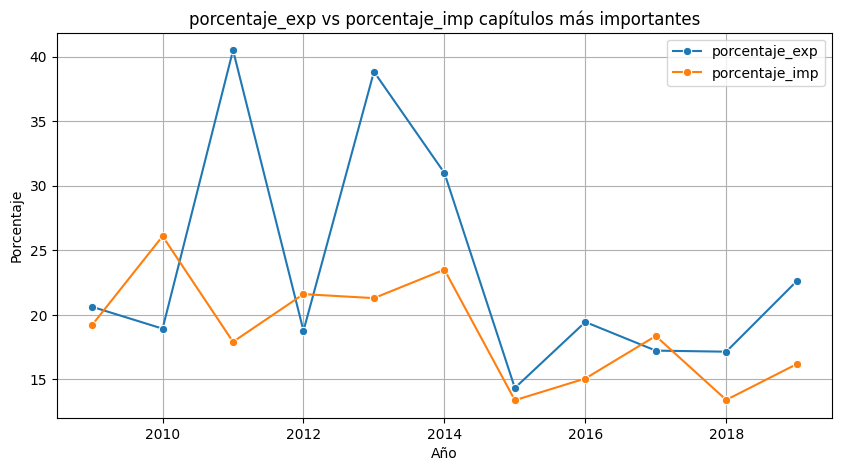

In [26]:
años = [2009, 2010, 2011, 2012, 2013,2014, 2015, 2016, 2017, 2018, 2019]

porcentaje_exp = [20.628531, 18.936257, 40.507670, 18.773306, 38.844094,30.999656, 14.341037, 19.452463, 17.234240, 17.152005, 22.615871]

porcentaje_imp = [19.220859, 26.099254, 17.913981, 21.611057, 21.301688,23.508977, 13.392031, 15.073102, 18.368581, 13.416463, 16.188671]

plt.figure(figsize=(10,5))
sns.lineplot(x=años, y=porcentaje_exp, marker="o", label="porcentaje_exp")
sns.lineplot(x=años, y=porcentaje_imp, marker="o", label="porcentaje_imp")
plt.title("porcentaje_exp vs porcentaje_imp capítulos más importantes")
plt.xlabel("Año")
plt.ylabel("Porcentaje")
plt.grid(True)
plt.legend()
plt.show()